Image shape: (480, 368)


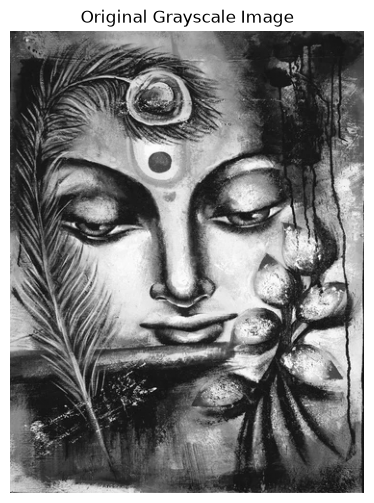

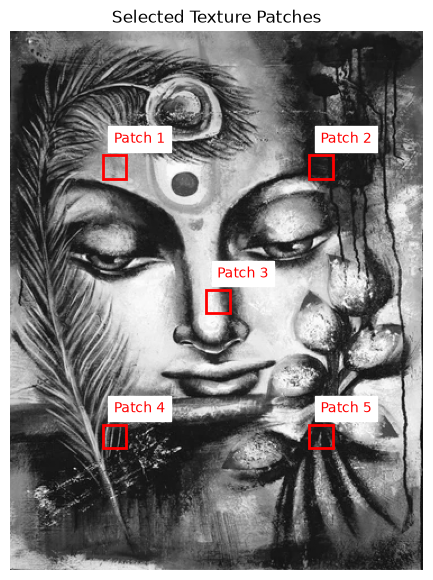

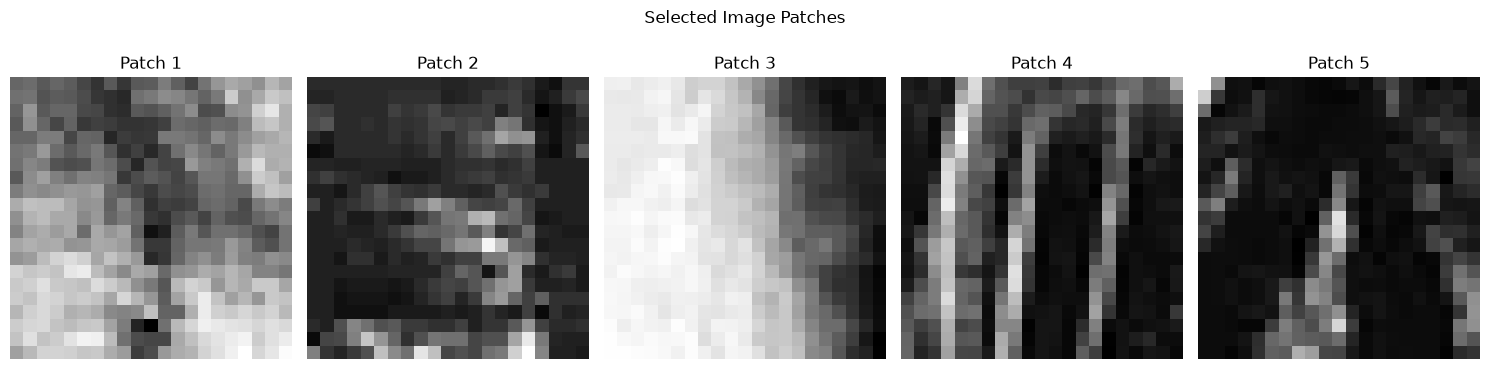


GLCM TEXTURE FEATURES
Patch     Contrast       Dissimilarity     Homogeneity       Energy         ASM            Correlation    
--------------------------------------------------------------------------------------------------------------
Patch 1   113.1720       8.0726            0.1233            0.0425         0.0018         0.7977         
Patch 2   49.2268        4.4491            0.3179            0.1146         0.0133         0.5515         
Patch 3   227.9138       10.9102           0.1143            0.0411         0.0017         0.9754         
Patch 4   1660.3817      27.0776           0.0903            0.0420         0.0018         0.5027         
Patch 5   440.3720       12.0974           0.2090            0.0846         0.0072         0.5814         


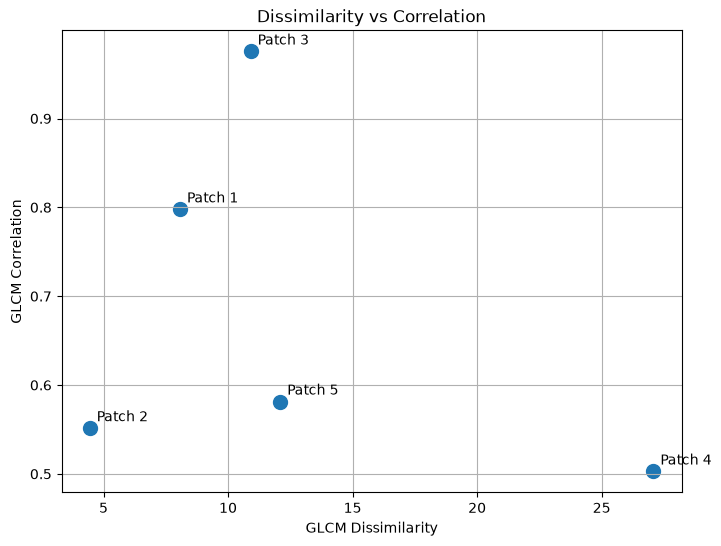

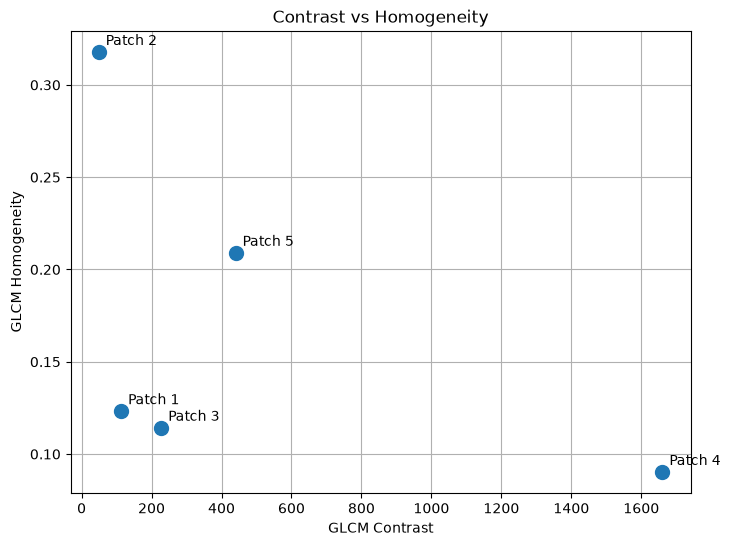

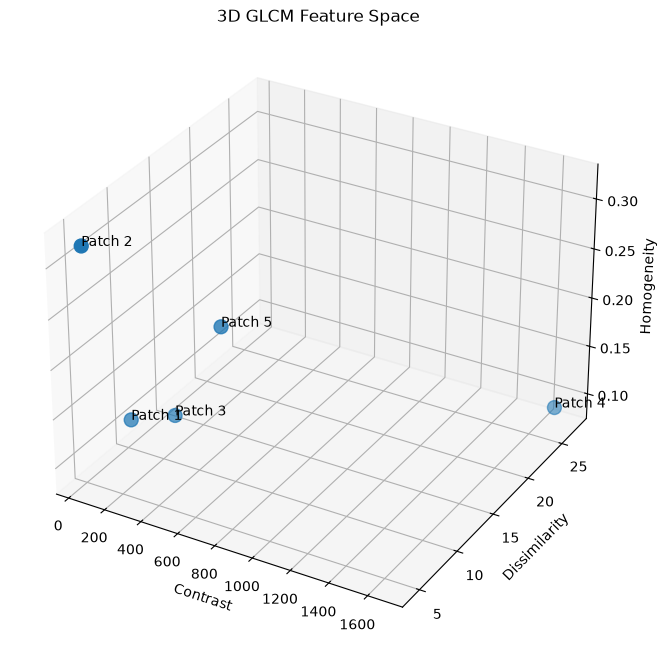

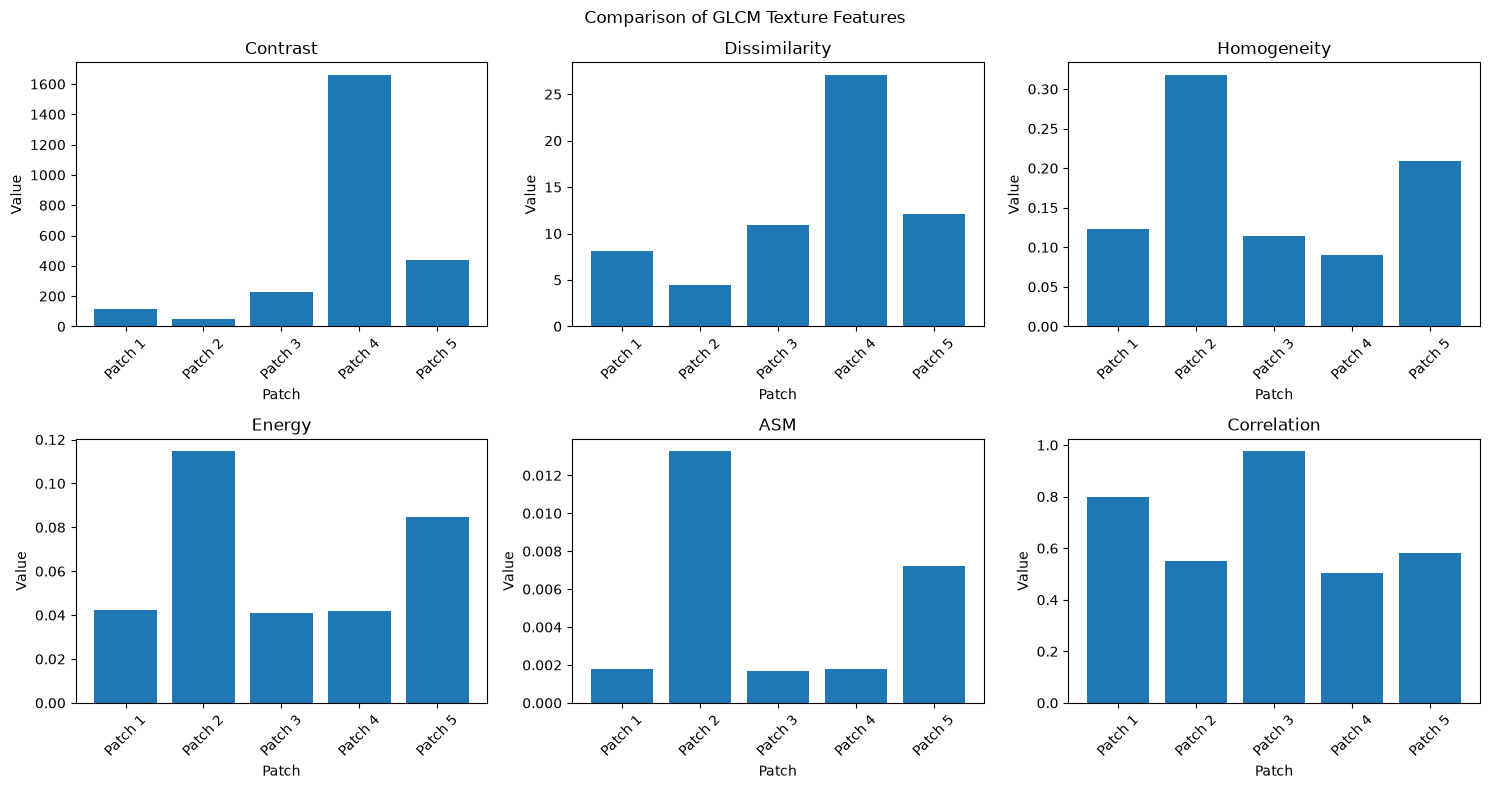

In [2]:
# EXPERIMENT 7
# Texture Analysis Using Gray Level Co-Occurrence Matrix (GLCM)

import numpy as np
import matplotlib.pyplot as plt
from skimage.io import imread
from skimage.color import rgb2gray
from skimage.feature import graycomatrix, graycoprops

# ---------------------------------------------------------
# 1. LOAD IMAGE
# ---------------------------------------------------------
image = imread("image.webp")

# Convert RGB image to grayscale
if len(image.shape) == 3:
    gray_image = rgb2gray(image)
    gray_image = (gray_image * 255).astype(np.uint8)
else:
    gray_image = image.astype(np.uint8)

print("Image shape:", gray_image.shape)

# ---------------------------------------------------------
# 2. DISPLAY ORIGINAL IMAGE
# ---------------------------------------------------------
plt.figure(figsize=(8, 6))
plt.imshow(gray_image, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")
plt.show()

# ---------------------------------------------------------
# 3. SELECT TEXTURE PATCHES
# ---------------------------------------------------------
PATCH_SIZE = 21

# Get image dimensions
height, width = gray_image.shape

# Automatically select 5 patches from different parts of the image
patch_locations = [
    (height // 4, width // 4),
    (height // 4, 3 * width // 4),
    (height // 2, width // 2),
    (3 * height // 4, width // 4),
    (3 * height // 4, 3 * width // 4)
]

patch_names = [
    "Patch 1",
    "Patch 2",
    "Patch 3",
    "Patch 4",
    "Patch 5"
]

# ---------------------------------------------------------
# 4. DISPLAY SELECTED PATCH LOCATIONS
# ---------------------------------------------------------
plt.figure(figsize=(9, 7))
plt.imshow(gray_image, cmap="gray")

for (row, col), name in zip(patch_locations, patch_names):
    rectangle = plt.Rectangle(
        (col - PATCH_SIZE // 2, row - PATCH_SIZE // 2),
        PATCH_SIZE,
        PATCH_SIZE,
        fill=False,
        linewidth=2,
        color="red"
    )
    plt.gca().add_patch(rectangle)
    plt.text(
        col,
        row - PATCH_SIZE,
        name,
        color="red",
        fontsize=10,
        backgroundcolor="white"
    )

plt.title("Selected Texture Patches")
plt.axis("off")
plt.show()

# ---------------------------------------------------------
# 5. EXTRACT PATCHES
# ---------------------------------------------------------
patches = []

for row, col in patch_locations:
    half = PATCH_SIZE // 2
    patch = gray_image[
        row - half:row + half + 1,
        col - half:col + half + 1
    ]
    patches.append(patch)

# ---------------------------------------------------------
# 6. DISPLAY INDIVIDUAL PATCHES
# ---------------------------------------------------------
fig, axes = plt.subplots(1, len(patches), figsize=(15, 4))

for i, (patch, name) in enumerate(zip(patches, patch_names)):
    axes[i].imshow(patch, cmap="gray")
    axes[i].set_title(name)
    axes[i].axis("off")

plt.suptitle("Selected Image Patches")
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 7. GLCM PARAMETERS
# ---------------------------------------------------------
distances = [1]
angles = [
    0,
    np.pi / 4,
    np.pi / 2,
    3 * np.pi / 4
]

# ---------------------------------------------------------
# 8. CALCULATE GLCM FEATURES
# ---------------------------------------------------------
results = []

for patch, name in zip(patches, patch_names):
    # Calculate GLCM
    glcm = graycomatrix(
        patch,
        distances=distances,
        angles=angles,
        levels=256,
        symmetric=True,
        normed=True
    )

    # Extract features
    contrast = graycoprops(glcm, "contrast").mean()
    dissimilarity = graycoprops(glcm, "dissimilarity").mean()
    homogeneity = graycoprops(glcm, "homogeneity").mean()
    energy = graycoprops(glcm, "energy").mean()
    ASM = graycoprops(glcm, "ASM").mean()
    correlation = graycoprops(glcm, "correlation").mean()

    results.append([
        name, contrast, dissimilarity, homogeneity, energy, ASM, correlation
    ])

# ---------------------------------------------------------
# 9. DISPLAY RESULTS
# ---------------------------------------------------------
print("\nGLCM TEXTURE FEATURES")
print("=" * 110)

print(
    f"{'Patch':<10}"
    f"{'Contrast':<15}"
    f"{'Dissimilarity':<18}"
    f"{'Homogeneity':<18}"
    f"{'Energy':<15}"
    f"{'ASM':<15}"
    f"{'Correlation':<15}"
)
print("-" * 110)

for result in results:
    print(
        f"{result[0]:<10}"
        f"{result[1]:<15.4f}"
        f"{result[2]:<18.4f}"
        f"{result[3]:<18.4f}"
        f"{result[4]:<15.4f}"
        f"{result[5]:<15.4f}"
        f"{result[6]:<15.4f}"
    )

# ---------------------------------------------------------
# 10. STORE FEATURES
# ---------------------------------------------------------
labels = [r[0] for r in results]
contrast = np.array([r[1] for r in results])
dissimilarity = np.array([r[2] for r in results])
homogeneity = np.array([r[3] for r in results])
energy = np.array([r[4] for r in results])
ASM = np.array([r[5] for r in results])
correlation = np.array([r[6] for r in results])

# ---------------------------------------------------------
# 11. 2D SCATTER PLOT (DISSIMILARITY vs CORRELATION)
# ---------------------------------------------------------
plt.figure(figsize=(8, 6))
plt.scatter(dissimilarity, correlation, s=100)

for i, label in enumerate(labels):
    plt.annotate(
        label,
        (dissimilarity[i], correlation[i]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("GLCM Dissimilarity")
plt.ylabel("GLCM Correlation")
plt.title("Dissimilarity vs Correlation")
plt.grid(True)
plt.show()

# ---------------------------------------------------------
# 12. 2D SCATTER PLOT (CONTRAST vs HOMOGENEITY)
# ---------------------------------------------------------
plt.figure(figsize=(8, 6))
plt.scatter(contrast, homogeneity, s=100)

for i, label in enumerate(labels):
    plt.annotate(
        label,
        (contrast[i], homogeneity[i]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("GLCM Contrast")
plt.ylabel("GLCM Homogeneity")
plt.title("Contrast vs Homogeneity")
plt.grid(True)
plt.show()

# ---------------------------------------------------------
# 13. 3D FEATURE SPACE
# ---------------------------------------------------------
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(contrast, dissimilarity, homogeneity, s=100)

for i, label in enumerate(labels):
    ax.text(contrast[i], dissimilarity[i], homogeneity[i], label)

ax.set_xlabel("Contrast")
ax.set_ylabel("Dissimilarity")
ax.set_zlabel("Homogeneity")
ax.set_title("3D GLCM Feature Space")
plt.show()

# ---------------------------------------------------------
# 14. FEATURE COMPARISON
# ---------------------------------------------------------
feature_names = [
    "Contrast", "Dissimilarity", "Homogeneity", "Energy", "ASM", "Correlation"
]
feature_values = [
    contrast, dissimilarity, homogeneity, energy, ASM, correlation
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, feature, values in zip(axes.ravel(), feature_names, feature_values):
    ax.bar(labels, values)
    ax.set_title(feature)
    ax.set_xlabel("Patch")
    ax.set_ylabel("Value")
    ax.tick_params(axis="x", rotation=45)

plt.suptitle("Comparison of GLCM Texture Features")
plt.tight_layout()
plt.show()
